In [23]:
import numpy as np

loaded_data = np.load('spiral_data.npz')

# Extract the arrays using the keys defined during export
K = loaded_data['K'].item()
x_train = loaded_data['x_train']
y_train = loaded_data['y_train']
x_test = loaded_data['x_test']
y_test = loaded_data['y_test']
x_final_test = loaded_data['x_final_test']
y_final_test = loaded_data['y_final_test']


In [24]:
%matplotlib inline

In [25]:
%run ./functions.ipynb

In [26]:
####################################################
#Next make a neural net to find ideal hyper-parameters for us
#{activation function, learning rate, number of hidden layers (capped), size of hidden layers (capped)
#####################################################

In [27]:
#should be careful with mapping, especially with categorical variable like activation function

In [28]:
%run ./nnFornnHP.ipynb

--- BEGINNING NEURAL ARCHITECTURE SEARCH ---
Starting Neural Architecture Search...
Episode 01 | Reward: 0.4825 | Params: {'activation': 'gauss', 'learning_rate': 2.0, 'num_layers': 3, 'layer_sizes': [8, 8, 4]}
Episode 02 | Reward: 0.3407 | Params: {'activation': 'sigmoid', 'learning_rate': 0.5, 'num_layers': 2, 'layer_sizes': [4, 4]}
Episode 03 | Reward: 0.5539 | Params: {'activation': 'gauss', 'learning_rate': 2.0, 'num_layers': 2, 'layer_sizes': [8, 4]}
Episode 04 | Reward: 0.2294 | Params: {'activation': 'relu', 'learning_rate': 2.0, 'num_layers': 3, 'layer_sizes': [4, 4, 4]}
Episode 05 | Reward: 0.4794 | Params: {'activation': 'relu', 'learning_rate': 0.1, 'num_layers': 2, 'layer_sizes': [8, 4]}
Episode 06 | Reward: 0.5050 | Params: {'activation': 'gauss', 'learning_rate': 0.5, 'num_layers': 3, 'layer_sizes': [4, 4, 4]}
Episode 07 | Reward: 0.2294 | Params: {'activation': 'softmax', 'learning_rate': 0.1, 'num_layers': 3, 'layer_sizes': [4, 8, 4]}
Episode 08 | Reward: 0.2773 | Para

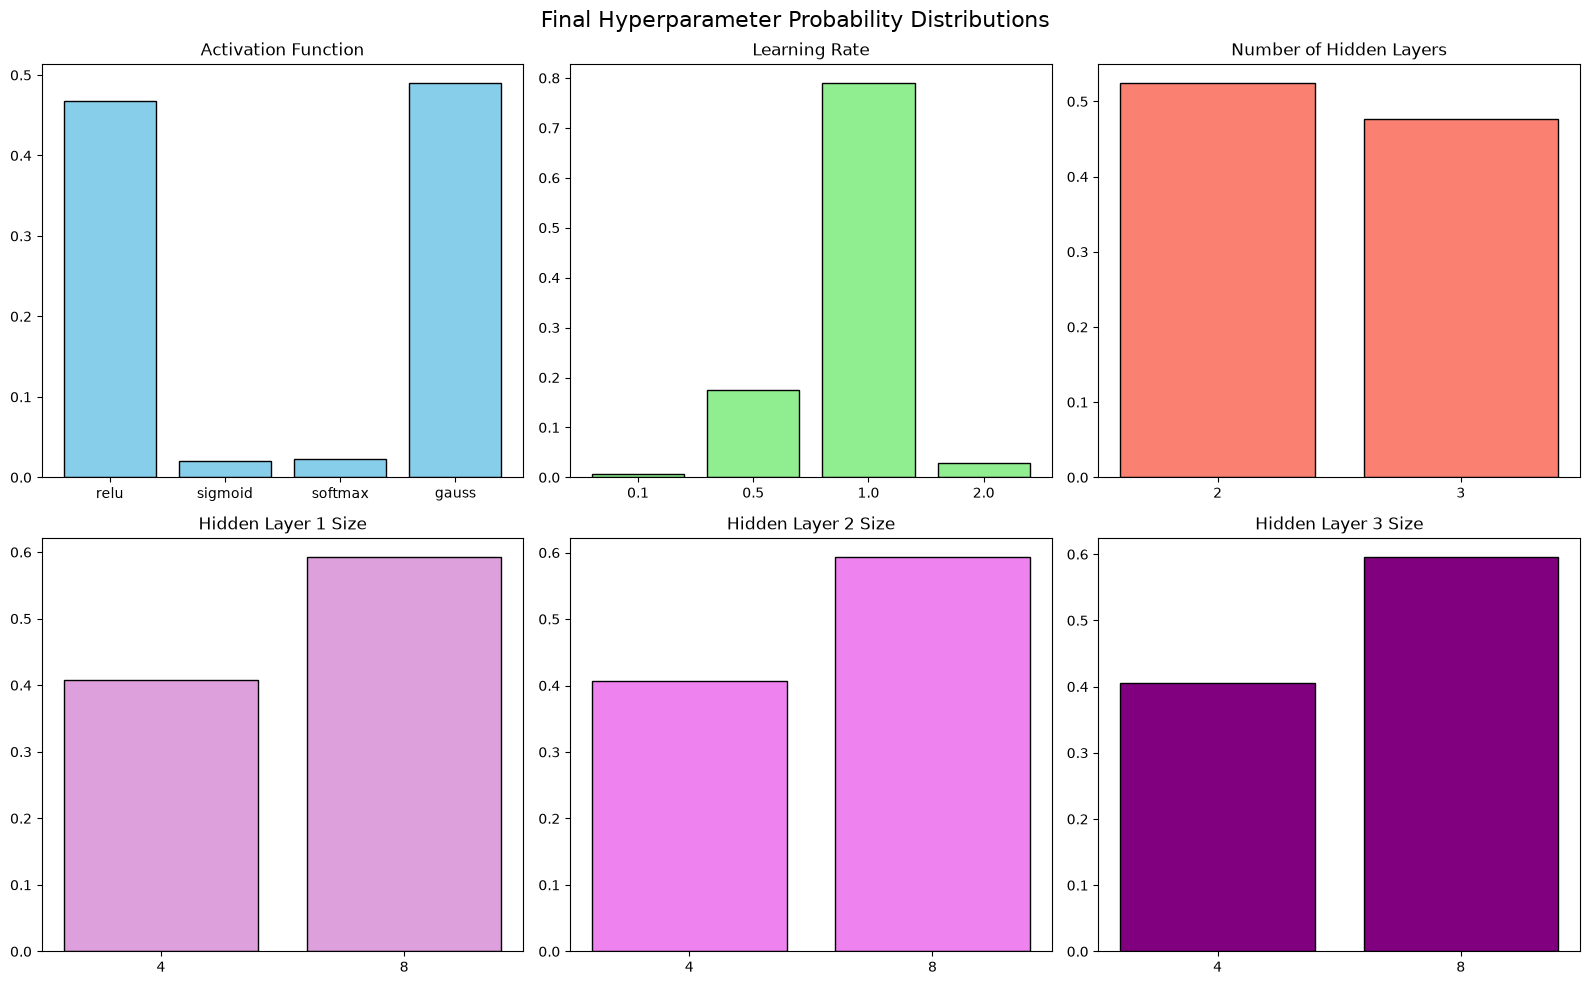

In [29]:
import math
import matplotlib.pyplot as plt

# 1. Define your search bounds here
pos_len = [2, 3]
pos_size = [4, 8]

print("--- BEGINNING NEURAL ARCHITECTURE SEARCH ---")
# Pass the search bounds into the optimizer
nas_search = NASOptimizer(pos_len, pos_size, controller_lr=0.01, beta=0.05, temperature=1.5)

optimal_params, act_probs, lr_probs, layers_probs, size_probs_list = nas_search.optimize(
    x_train, y_train, x_test, y_test, K, search_episodes=100, N_epochs=1000
)

best_act = optimal_params['activation']
best_lr = optimal_params['learning_rate']
best_layers = optimal_params['num_layers']
mid_size_array = optimal_params['layer_sizes']

print("\n--- TRAINING FINAL MODEL WITH OPTIMAL HYPERPARAMETERS ---")
print(f"Configuration: Act={best_act.upper()}, LR={best_lr}, Layers={best_layers}, Array={mid_size_array}")

# --- Dynamically scaled Plotting Grid ---
max_layers = nas_search.controller.max_layers
total_plots = 3 + max_layers # 3 fixed plots (act, lr, num_layers) + independent sizes

# Define a 3-column grid and calculate how many rows are needed
cols = 3
rows = math.ceil(total_plots / cols)

fig, axs = plt.subplots(rows, cols, figsize=(16, 5 * rows))
fig.suptitle('Final Hyperparameter Probability Distributions', fontsize=16)

# Flatten the axes array so we can iterate through it easily
axs = axs.flatten()

activation_labels = list(nas_search.controller.act_map.values())
lr_labels = [str(v) for v in nas_search.controller.lr_map.values()]
layers_labels = [str(v) for v in nas_search.controller.layers_map.values()]
size_labels = [str(v) for v in nas_search.controller.size_map.values()]

axs[0].bar(activation_labels, act_probs, color='skyblue', edgecolor='black')
axs[0].set_title('Activation Function')

axs[1].bar(lr_labels, lr_probs, color='lightgreen', edgecolor='black')
axs[1].set_title('Learning Rate')

axs[2].bar(layers_labels, layers_probs, color='salmon', edgecolor='black')
axs[2].set_title('Number of Hidden Layers')

# Plot a graph for every potential hidden layer
colors = ['plum', 'violet', 'purple', 'orchid', 'mediumpurple']
for i in range(max_layers):
    c = colors[i % len(colors)]
    axs[3 + i].bar(size_labels, size_probs_list[i], color=c, edgecolor='black')
    axs[3 + i].set_title(f'Hidden Layer {i+1} Size')

# Turn off any empty subplots to keep the image clean
for i in range(total_plots, len(axs)):
    fig.delaxes(axs[i])

plt.tight_layout()
plt.savefig('hyperparameter_distributions.pdf', bbox_inches="tight")
plt.show()

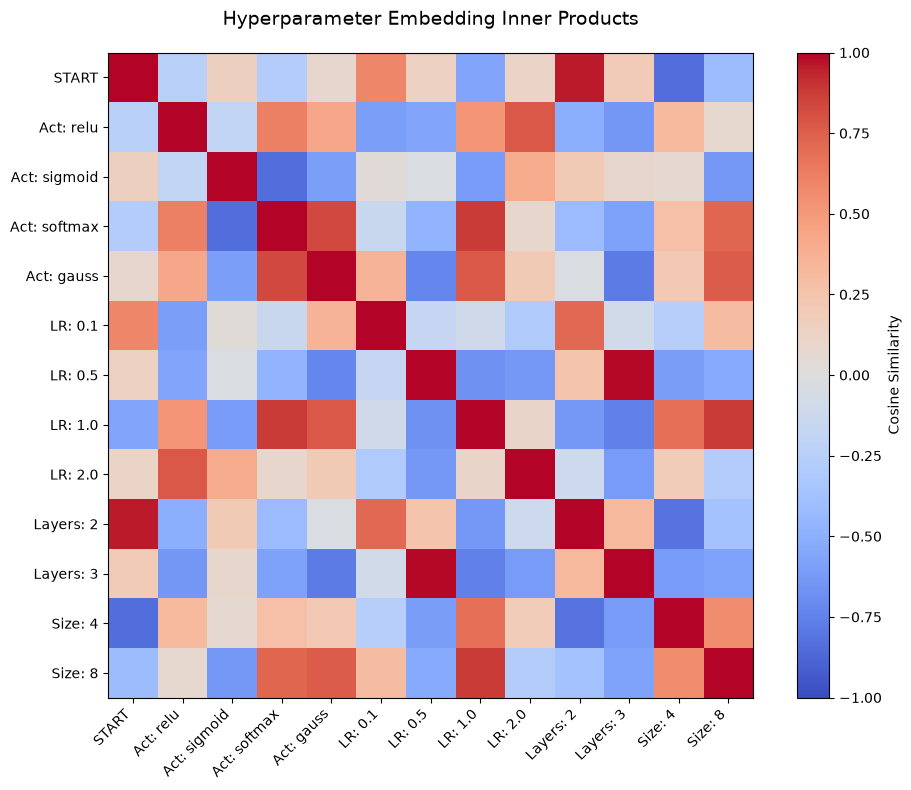

In [30]:
plot_embedding_inner_products(nas_search.controller)

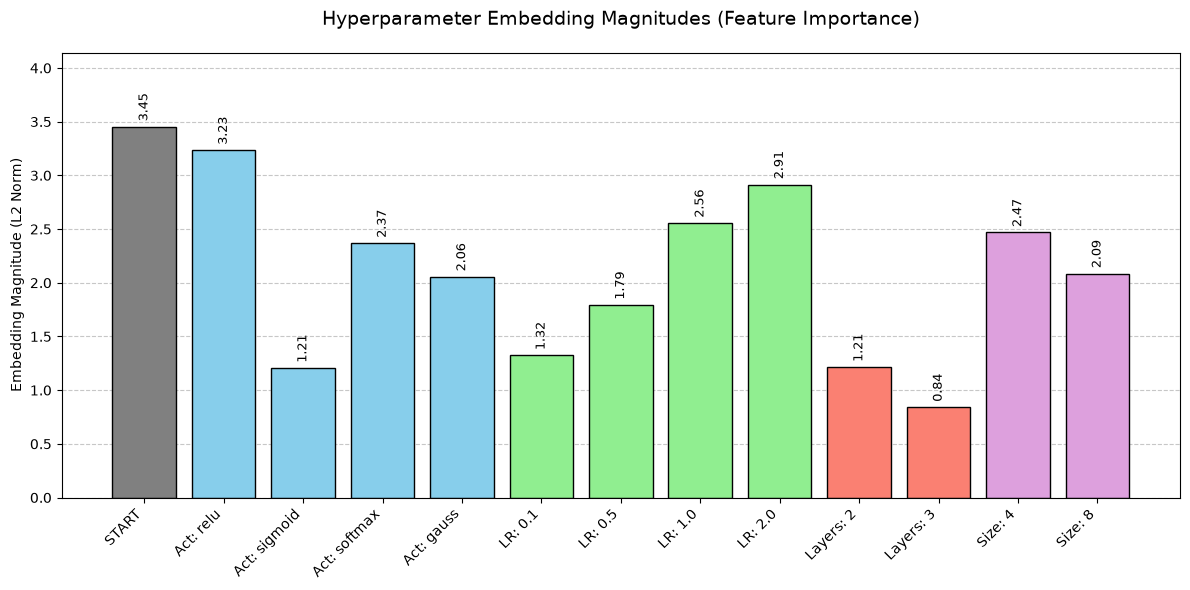

In [31]:
plot_embedding_magnitudes(nas_search.controller)

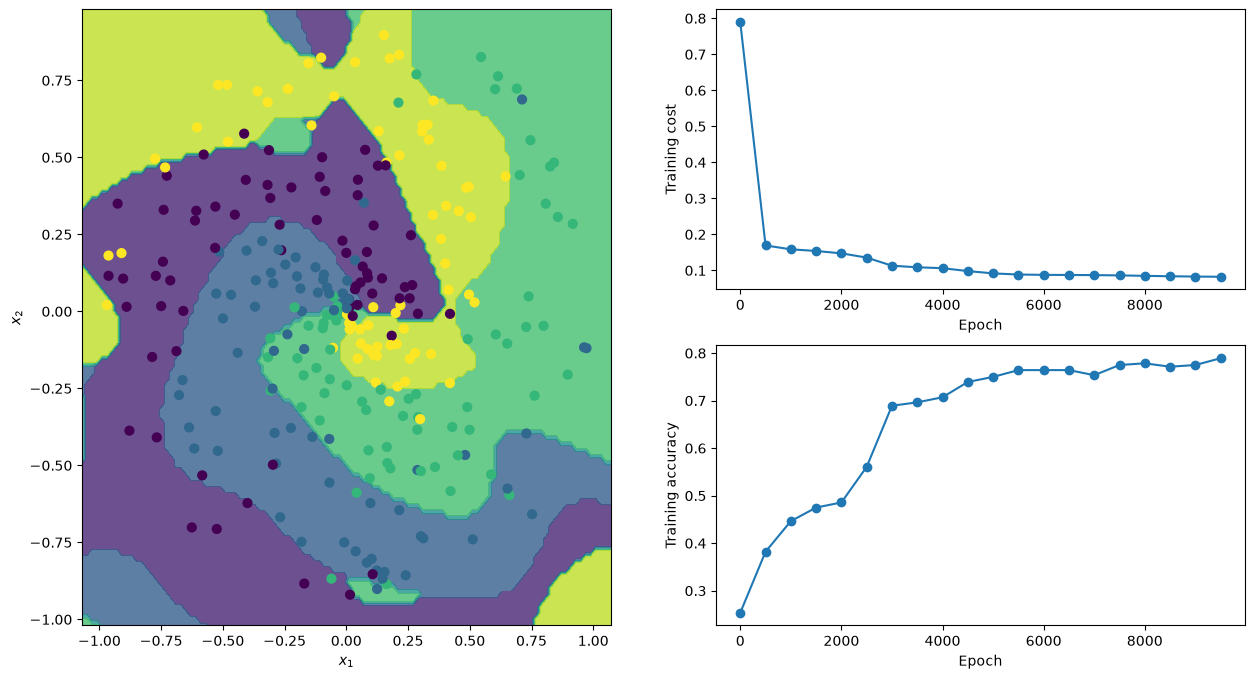

train:
 [GAUSS] Iteration 9999:
  Training cost 0.081189
  Training accuracy 0.789286



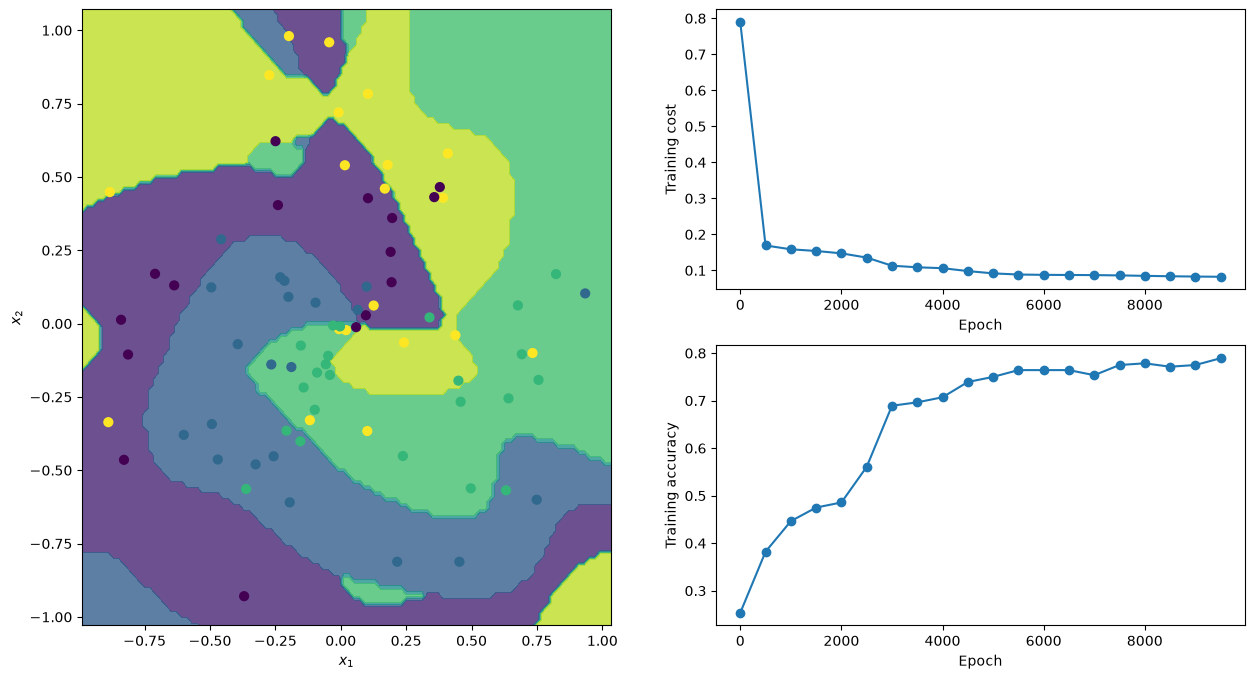

test:
 [GAUSS] Iteration 9999:
  Training cost 0.081189
  Training accuracy 0.789286

Saved spiral_results_gauss.pdf
Final GAUSS Training cost 0.081189
Final GAUSS TEST accuracy 0.600000

--------------------------------------------------


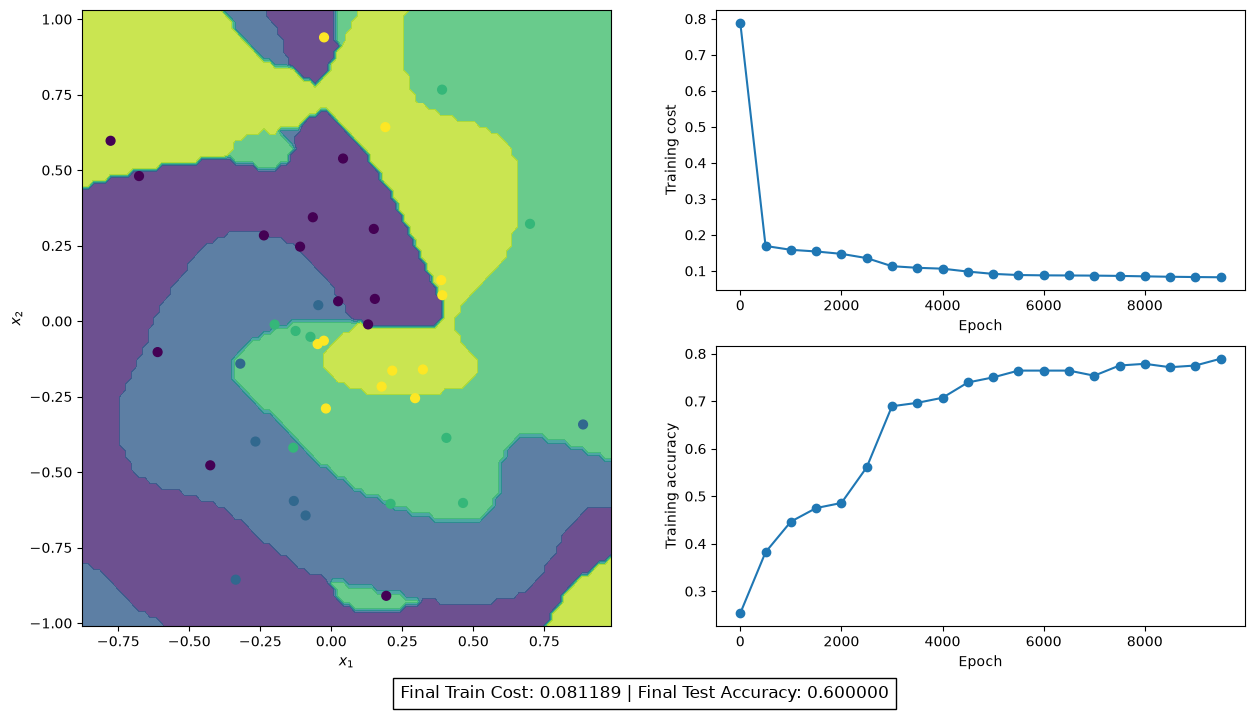

In [32]:
#test solution with test_final data

# --- setup and train selected hyperparameters on training data ---
N_epochs = 10000
act = optimal_params['activation']
mid_size_array = optimal_params['layer_sizes']
lr = optimal_params['learning_rate']

# Setup model using training data
model, x_train_tensor, y_onehot, optimizer, cost_func = setup_model_and_data(
    x_train, y_train, K, mid_size_array, lr, N_epochs, act
)

epoch_list    = []
cost_training = []
acc_training  = []

### Train for several epochs: ###
for epoch in range(N_epochs):

    optimizer.zero_grad()
    NN_output = model(x_train_tensor) # Train on x_train
    cost = cost_func(NN_output, y_onehot)
    cost.backward()
    optimizer.step()

    ### Update the plot and print results every 500 epochs: ###
    if epoch % 500 == 0:
        predicted_class = np.argmax(NN_output.detach().numpy(), axis=1)
        accuracy = np.mean(predicted_class == y_train)

        epoch_list.append(epoch)
        cost_training.append(cost.detach().numpy())
        acc_training.append(accuracy)

    if(epoch == N_epochs-1):
        ### Update the plot of the resulting classifier: ###
        fig = plt.figure(figsize=(15,8))
        fig.subplots_adjust(hspace=.3, wspace=.3)
        plt.clf()

        updatePlot(model,epoch_list,cost_training,acc_training,x_train,y_train)

        plt.show()
#        display.display(plt.gcf())
        print(f"train:\n [{act.upper()}] Iteration {epoch}:\n  Training cost {cost:.6f}\n  Training accuracy {accuracy:.6f}\n")

        fig = plt.figure(figsize=(15,8))
        fig.subplots_adjust(hspace=.3, wspace=.3)
        plt.clf()
        updatePlot(model,epoch_list,cost_training,acc_training,x_test,y_test)

        plt.show()
#        display.display(plt.gcf())
        print(f"test:\n [{act.upper()}] Iteration {epoch}:\n  Training cost {cost:.6f}\n  Training accuracy {accuracy:.6f}\n")

        #Stop clearing the output on the very last step so the final plot stays visible
        #if epoch < N_epochs - 500:
        #    display.clear_output(wait=True)

# --- evaluate on final test data ---
# Set the model to evaluation mode
model.eval()
x_final_test_tensor = torch.tensor(x_final_test, dtype=torch.float)

# Turn off gradients for the test pass
with torch.no_grad():
    final_output = model(x_final_test_tensor)
    final_predicted_class = np.argmax(final_output.numpy(), axis=1)

    # Calculate final accuracy against y_final_test
    final_accuracy = np.mean(final_predicted_class == y_final_test)


fig = plt.figure(figsize=(15,8))
fig.subplots_adjust(hspace=.3, wspace=.3)
plt.clf()
updatePlot(model,epoch_list,cost_training,acc_training,x_final_test,y_final_test)

metrics_text = f"Final Train Cost: {cost:.6f} | Final Test Accuracy: {final_accuracy:.6f}"
plt.figtext(0.5, 0.02, metrics_text, ha="center", fontsize=12,
            bbox={"facecolor":"white", "pad":5})

#Dynamically name the file based on the activation function
filename = f'spiral_results_{act}.pdf'
plt.savefig(filename, bbox_inches="tight")

print(f"Saved {filename}")
print(f"Final {act.upper()} Training cost {cost:.6f}\nFinal {act.upper()} TEST accuracy {final_accuracy:.6f}\n")
print("-" * 50)